In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('Churn_Modelling.csv')

df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [2]:
print(df.shape)
print(df.isnull().sum())

(10000, 14)
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [3]:
# remove unnecessary columns
df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1, inplace=True)

# separate features and target
x = df.drop('Exited', axis=1)
y = df['Exited']

In [4]:
# convert categorical columns into numerical values
x = pd.get_dummies(x, columns=['Geography', 'Gender'], drop_first=True)
x.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False


In [5]:
# split train and test
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [8]:
# normalize the data
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [10]:
!pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 1.8/384.1 MB 9.2 MB/s eta 0:00:42
   ---------------------------------------- 4.2/384.1 MB 9.6 MB/s eta 0:00:40
    --------------------------------------- 6.3/384.1 MB 9.8 MB/s eta 0:00:39
    --------------------------------------- 8.4/384.1 MB 9.9 MB/s eta 0:00:38
   - -------------------------------------- 10.7/384.1 MB 10.0 MB/s eta 0:00:38
   - -------------------------------------- 12.8/384.1 MB 10.0 MB/s eta 0:00:38
   - -------------------------------------- 15.2/384.1 MB 10.1 MB/s eta 0:00:37
   - -------------------------------------- 17.6/384.1 MB 10.1 MB/s eta 0:00:37
   -- ------------------------------------- 19.7/384.1 MB 10.2 MB/s eta 0:00:36
   -- ------------------------------------- 22.0/384.1 MB 10.2 MB/s eta 0:00:36
   -- ------------------------------------- 24.1/384.1 MB 1

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
google-api-core 2.25.2 requires protobuf!=3.20.0,!=3.20.1,!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<7.0.0,>=3.19.5, but you have protobuf 7.36.2 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.

[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
# initialize and build the model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential()

model.add(Dense(16, activation='relu', input_shape=(x_train.shape[1],)))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

C:\Users\mahes\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\core\dense.py:97: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
# compile the model
model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

In [13]:
# train the model
history = model.fit(x_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

Epoch 1/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.7366 - loss: 0.5698 - val_accuracy: 0.7981 - val_loss: 0.4817
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7955 - loss: 0.4669 - val_accuracy: 0.8025 - val_loss: 0.4399
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8033 - loss: 0.4421 - val_accuracy: 0.8175 - val_loss: 0.4248
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8111 - loss: 0.4311 - val_accuracy: 0.8244 - val_loss: 0.4164
Epoch 5/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8192 - loss: 0.4236 - val_accuracy: 0.8300 - val_loss: 0.4098
Epoch 6/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8231 - loss: 0.4153 - val_accuracy: 0.8394 - val_loss: 0.4012
Epoch 7/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8303 - loss: 0.4042 - val_accuracy: 0.8494 - val_loss: 0.3904
Epoch 8/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8378 - loss: 0.3898 - val_accuracy: 0.

In [15]:


# improve the model
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor = 'val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8634 - loss: 0.3340 - val_accuracy: 0.8537 - val_loss: 0.3437
Epoch 2/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8636 - loss: 0.3330 - val_accuracy: 0.8525 - val_loss: 0.3432
Epoch 3/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8636 - loss: 0.3320 - val_accuracy: 0.8506 - val_loss: 0.3428
Epoch 4/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8639 - loss: 0.3312 - val_accuracy: 0.8525 - val_loss: 0.3426
Epoch 5/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8639 - loss: 0.3304 - val_accuracy: 0.8525 - val_loss: 0.3425
Epoch 6/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8639 - loss: 0.3297 - val_accuracy: 0.8525 - val_loss: 0.3422
Epoch 7/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8645 - loss: 0.3290 - val_accuracy: 0.8512 - val_loss: 0.3420
Epoch 8/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8641 - loss: 0.3284 - val_accuracy: 0.

In [16]:

# calculate accuracy and confusion matrix
from sklearn.metrics import accuracy_score, confusion_matrix

y_pred = model.predict(x_test)
y_pred = (y_pred > 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test,y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test,y_pred))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Accuracy: 0.4685
Confusion Matrix:
[[651 956]
 [107 286]]


In [21]:
# display predictions
for i in range(10):
    if y_pred[i] == 1:
        print("Customer will leave")
    else:
        print("Customer will stay")

Customer will leave
Customer will stay
Customer will stay
Customer will leave
Customer will leave
Customer will stay
Customer will leave
Customer will leave
Customer will leave
Customer will leave


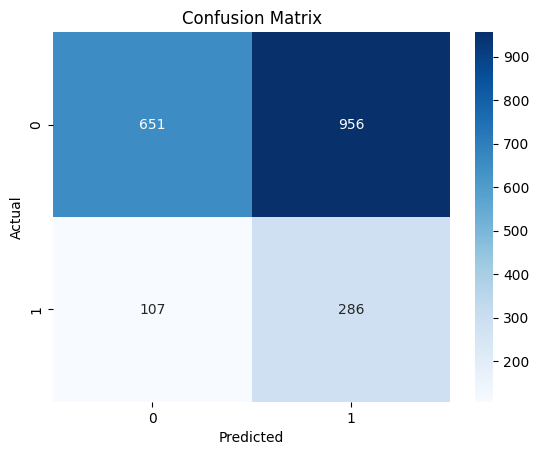

In [19]:
# Display confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap='Blues', fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()